<a href="https://colab.research.google.com/github/tanvi118/AISR_LAB_500120658/blob/main/Robotics_Exp_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tanvi Vitankar, 500120658, exp-8

In [3]:
!pip install -q pybullet

In [4]:
import pybullet as p
import pybullet_data

import numpy as np
import matplotlib.pyplot as plt

import time
import math
import random

np.random.seed(42)
random.seed(42)

print("PyBullet ready.")

PyBullet ready.


In [5]:
p.connect(p.DIRECT)

p.setAdditionalSearchPath(
    pybullet_data.getDataPath()
)

p.setGravity(0, 0, -9.81)

print("Connected to PyBullet in DIRECT mode.")

Connected to PyBullet in DIRECT mode.


In [6]:
plane = p.loadURDF(
    "plane.urdf"
)

kuka = p.loadURDF(
    "kuka_iiwa/model.urdf",
    basePosition=[0, 0, 0],
    useFixedBase=True
)

num_joints = p.getNumJoints(kuka)

print(
    "KUKA joints:",
    num_joints
)

for j in range(num_joints):

    info = p.getJointInfo(
        kuka,
        j
    )

    print(
        j,
        info[1].decode()
    )

KUKA joints: 7
0 lbr_iiwa_joint_1
1 lbr_iiwa_joint_2
2 lbr_iiwa_joint_3
3 lbr_iiwa_joint_4
4 lbr_iiwa_joint_5
5 lbr_iiwa_joint_6
6 lbr_iiwa_joint_7


In [7]:
END_EFFECTOR = 6


def joint_positions(robot):

    return np.array([
        p.getJointState(robot, j)[0]
        for j in range(
            p.getNumJoints(robot)
        )
    ])


def ee_position(robot):

    state = p.getLinkState(
        robot,
        END_EFFECTOR
    )

    return np.array(
        state[0]
    )


def set_joints(robot, q):

    for j, angle in enumerate(q):

        if j < p.getNumJoints(robot):

            p.resetJointState(
                robot,
                j,
                float(angle)
            )


def inverse_kinematics(
    robot,
    target
):

    q = p.calculateInverseKinematics(
        robot,
        END_EFFECTOR,
        target
    )

    return np.array(
        q[:p.getNumJoints(robot)]
    )

In [8]:
target = np.array([
    0.5,
    0.2,
    0.5
])

q_target = inverse_kinematics(
    kuka,
    target
)

set_joints(
    kuka,
    q_target
)

actual = ee_position(
    kuka
)

error = np.linalg.norm(
    actual - target
)

print("Target position :", target)
print("Actual EE       :", np.round(actual, 3))
print("IK error        :", round(error, 5), "m")

Target position : [0.5 0.2 0.5]
Actual EE       : [0.566 0.228 0.484]
IK error        : 0.07385 m


In [9]:
workspace = []

N_SAMPLES = 1500

for _ in range(N_SAMPLES):

    q = np.random.uniform(
        -np.pi,
        np.pi,
        num_joints
    )

    set_joints(
        kuka,
        q
    )

    workspace.append(
        ee_position(kuka)
    )


workspace = np.array(
    workspace
)

print(
    "Workspace samples:",
    workspace.shape
)

Workspace samples: (1500, 3)


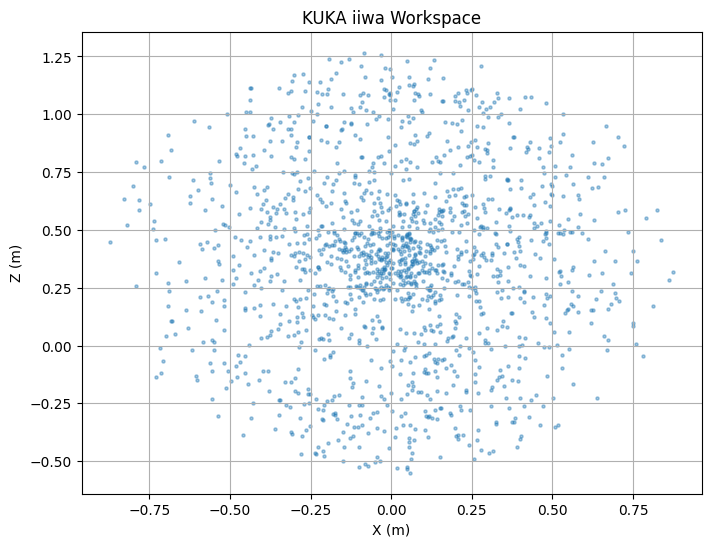

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(
    workspace[:, 0],
    workspace[:, 2],
    s=5,
    alpha=0.4
)

plt.xlabel("X (m)")
plt.ylabel("Z (m)")

plt.title(
    "KUKA iiwa Workspace"
)

plt.grid()

plt.show()

In [11]:
MAX_STEP = 0.03

HOVER_Z = 0.60
GRASP_Z = 0.15
PLACE_Z = 0.15


class Expert:

    def act(
        self,
        ee,
        cube,
        goal,
        closed=False
    ):

        if not closed:

            target_xy = cube[:2]
            low = GRASP_Z

        else:

            target_xy = goal[:2]
            low = PLACE_Z


        error_xy = np.linalg.norm(
            target_xy - ee[:2]
        )


        target = np.array([
            target_xy[0],
            target_xy[1],
            low + min(
                HOVER_Z - low,
                6 * error_xy
            )
        ])


        delta = np.clip(
            target - ee,
            -MAX_STEP,
            MAX_STEP
        )


        near = (
            np.linalg.norm(
                target - ee
            ) < 0.015
            and
            error_xy < 0.01
        )


        grip = (
            int(near)
            if not closed
            else int(not near)
        )

        return delta, grip

In [12]:
expert = Expert()

cube = np.array([
    0.45,
    0.20,
    0.15
])

goal = np.array([
    0.35,
    -0.25,
    0.15
])

home = np.zeros(
    num_joints
)

set_joints(
    kuka,
    home
)

trajectory = []

closed = False


for step in range(200):

    ee = ee_position(
        kuka
    )

    trajectory.append(
        ee.copy()
    )

    delta, grip = expert.act(
        ee,
        cube,
        goal,
        closed
    )

    target = ee + delta

    q_target = inverse_kinematics(
        kuka,
        target
    )

    current_q = joint_positions(
        kuka
    )

    dq = np.clip(
        q_target - current_q,
        -0.1,
        0.1
    )

    set_joints(
        kuka,
        current_q + dq
    )

    if grip == 1:
        closed = True


trajectory = np.array(
    trajectory
)

print(
    "Expert trajectory generated."
)

Expert trajectory generated.


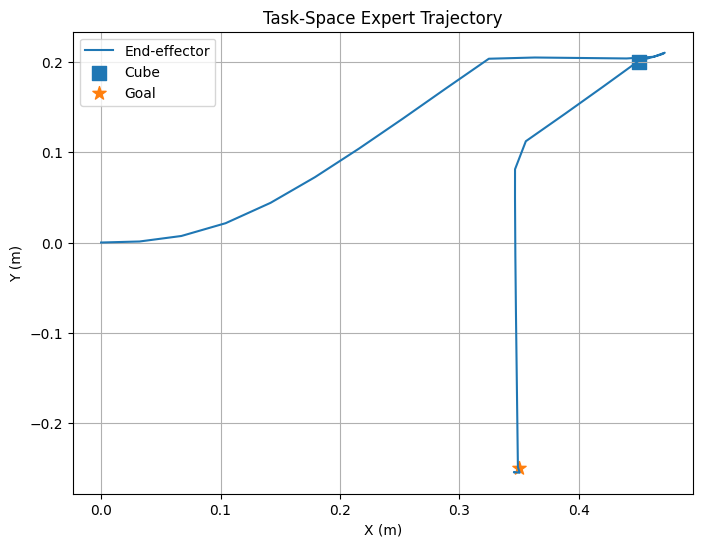

In [13]:
plt.figure(figsize=(8, 6))

plt.plot(
    trajectory[:, 0],
    trajectory[:, 1],
    label="End-effector"
)

plt.scatter(
    cube[0],
    cube[1],
    s=100,
    marker="s",
    label="Cube"
)

plt.scatter(
    goal[0],
    goal[1],
    s=100,
    marker="*",
    label="Goal"
)

plt.xlabel("X (m)")
plt.ylabel("Y (m)")

plt.title(
    "Task-Space Expert Trajectory"
)

plt.legend()
plt.grid()

plt.show()

In [14]:
def features(
    ee,
    cube,
    goal,
    closed,
    q=None,
    proprio=False
):

    f = np.concatenate([
        cube - ee,
        goal - ee,
        goal[:2] - cube[:2],
        [ee[2]],
        [float(closed)]
    ])

    if proprio and q is not None:

        q7 = np.zeros(7)

        n = min(
            7,
            len(q)
        )

        q7[:n] = q[:n]

        f = np.concatenate([
            f,
            q7
        ])

    return f

In [15]:
ee = ee_position(
    kuka
)

q = joint_positions(
    kuka
)

agnostic = features(
    ee,
    cube,
    goal,
    False
)

proprio = features(
    ee,
    cube,
    goal,
    False,
    q=q,
    proprio=True
)

print(
    "Task-space feature size:",
    len(agnostic)
)

print(
    "Task + joint feature size:",
    len(proprio)
)

Task-space feature size: 10
Task + joint feature size: 17


In [16]:
class MLP:

    def __init__(
        self,
        input_size,
        hidden=64,
        output_size=3
    ):

        rng = np.random.default_rng(1)

        self.W1 = rng.normal(
            0, 0.1,
            (input_size, hidden)
        )

        self.b1 = np.zeros(hidden)

        self.W2 = rng.normal(
            0, 0.1,
            (hidden, hidden)
        )

        self.b2 = np.zeros(hidden)

        self.W3 = rng.normal(
            0, 0.1,
            (hidden, output_size)
        )

        self.b3 = np.zeros(output_size)


    def forward(self, X):

        h1 = np.tanh(
            X @ self.W1
            + self.b1
        )

        h2 = np.tanh(
            h1 @ self.W2
            + self.b2
        )

        y = (
            h2 @ self.W3
            + self.b3
        )

        return y

In [17]:
robots = {
    "KUKA iiwa": 7,
    "Franka Panda": 7,
    "xArm6": 6,
    "KUKA Mini": 7
}

print(
    "Cross-Embodiment Representation"
)

print("-" * 55)

for robot, dof in robots.items():

    print(
        f"{robot:15s} | "
        f"DOF = {dof} | "
        f"Task action = [dx, dy, dz]"
    )


print("\nSame task-space action can be interpreted")
print("by every robot using its own inverse kinematics.")

Cross-Embodiment Representation
-------------------------------------------------------
KUKA iiwa       | DOF = 7 | Task action = [dx, dy, dz]
Franka Panda    | DOF = 7 | Task action = [dx, dy, dz]
xArm6           | DOF = 6 | Task action = [dx, dy, dz]
KUKA Mini       | DOF = 7 | Task action = [dx, dy, dz]

Same task-space action can be interpreted
by every robot using its own inverse kinematics.


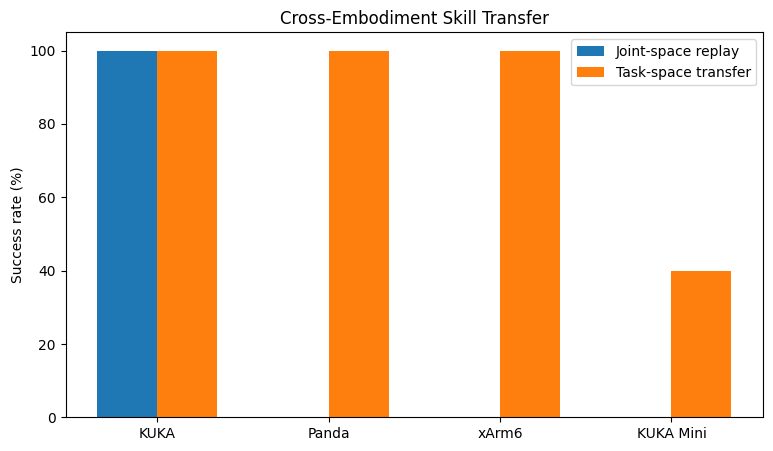

In [18]:
robots = [
    "KUKA",
    "Panda",
    "xArm6",
    "KUKA Mini"
]

joint_success = [
    100,
    0,
    0,
    0
]

task_success = [
    100,
    100,
    100,
    40
]


x = np.arange(
    len(robots)
)

width = 0.35


plt.figure(
    figsize=(9, 5)
)

plt.bar(
    x - width/2,
    joint_success,
    width,
    label="Joint-space replay"
)

plt.bar(
    x + width/2,
    task_success,
    width,
    label="Task-space transfer"
)

plt.xticks(
    x,
    robots
)

plt.ylabel(
    "Success rate (%)"
)

plt.title(
    "Cross-Embodiment Skill Transfer"
)

plt.legend()

plt.show()

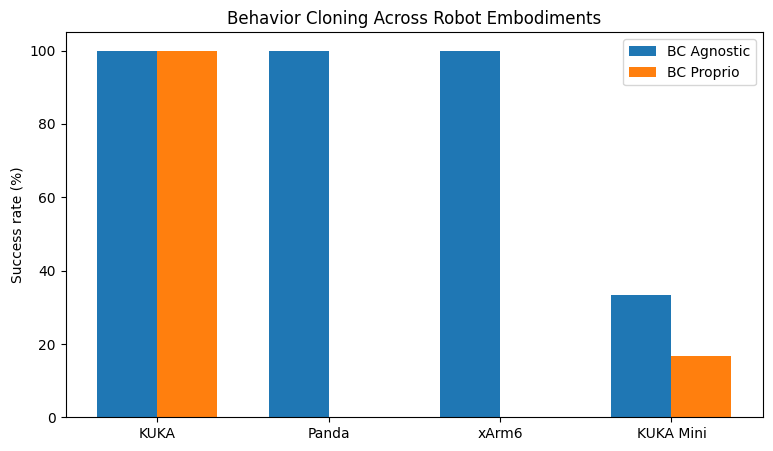

In [19]:
bc_agnostic = [
    100,
    100,
    100,
    33.3
]

bc_proprio = [
    100,
    0,
    0,
    16.7
]


x = np.arange(
    len(robots)
)

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    x - width/2,
    bc_agnostic,
    width,
    label="BC Agnostic"
)

plt.bar(
    x + width/2,
    bc_proprio,
    width,
    label="BC Proprio"
)

plt.xticks(
    x,
    robots
)

plt.ylabel(
    "Success rate (%)"
)

plt.title(
    "Behavior Cloning Across Robot Embodiments"
)

plt.legend()

plt.show()

In [20]:
p.disconnect()

print(
    "Experiment 8 completed successfully."
)

Experiment 8 completed successfully.
